**Assignment 3 – Object Detection and Segmentation**

Introduction

The objective of this assignment is to explore three computer vision tasks: object segmentation, image annotation, and object detection. The Oxford-IIIT Pet dataset is used to visualize segmentation masks, the Raccoon dataset is used to inspect bounding-box annotations and generate masks, and YOLO11 is used for object detection and fine-tuning on the African Wildlife dataset.

The notebook follows the three parts of the assignment and includes visual results and observations from the experiments.

In [18]:
import tensorflow_datasets as tfds

# Load the oxford_iiit_pet dataset
dataset, info = tfds.load("oxford_iiit_pet", with_info=True, as_supervised=False)

# Split into training and testing sets
train_dataset = dataset['train']
test_dataset = dataset['test']

# Inspect dataset features and sample counts
print("Dataset Info:", info.features)
print("Number of training examples:", info.splits['train'].num_examples)
print("Number of test examples:", info.splits['test'].num_examples)


Dataset Info: FeaturesDict({
    'file_name': Text(shape=(), dtype=string),
    'head_bbox': BBoxFeature(shape=(4,), dtype=float32),
    'image': Image(shape=(None, None, 3), dtype=uint8),
    'label': ClassLabel(shape=(), dtype=int64, num_classes=37),
    'segmentation_mask': Image(shape=(None, None, 1), dtype=uint8),
    'species': ClassLabel(shape=(), dtype=int64, num_classes=2),
})
Number of training examples: 3680
Number of test examples: 3669


In [19]:
import tensorflow as tf


# Define the resizing function
def preprocess(sample):
    # Resize image using bilinear interpolation and normalize pixel values to [0, 1]
    image = tf.image.resize(sample['image'], (128, 128))
    image = tf.cast(image, tf.float32) / 255.0

    # Resize mask using nearest-neighbor interpolation to preserve integer class labels (1, 2, 3)
    mask = tf.image.resize(sample['segmentation_mask'], (128, 128), method='nearest')

    return image, mask


# Map the resizing function to the dataset
processed_train = train_dataset.map(preprocess)

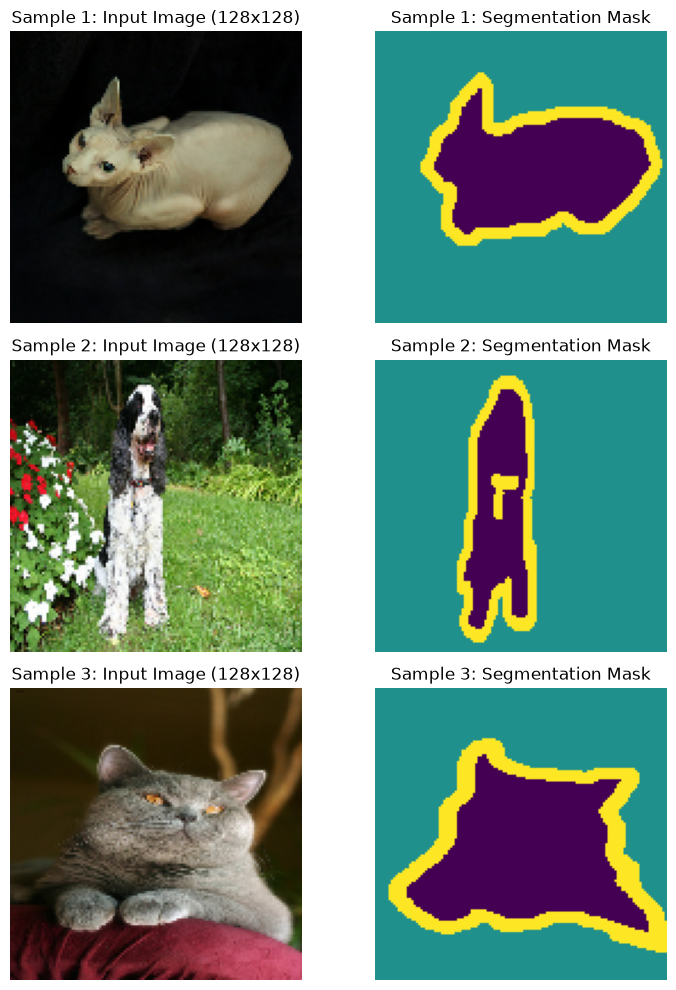

In [23]:
# Display the first 3 samples
import matplotlib.pyplot as plt
import os

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'  # '2' hides INFO and WARNING messages, showing only ERRORS

plt.figure(figsize=(8, 10))

for i, (image, mask) in enumerate(processed_train.take(3)):
    plt.subplot(3, 2, 2 * i + 1)
    plt.imshow(image)
    plt.title(f"Sample {i + 1}: Input Image (128x128)")
    plt.axis('off')

    plt.subplot(3, 2, 2 * i + 2)
    plt.imshow(tf.squeeze(mask))
    plt.title(f"Sample {i + 1}: Segmentation Mask")
    plt.axis('off')

plt.tight_layout()
plt.show()

**Part 2 – Image Annotation Using the Raccoon Dataset**


The Raccoon dataset contains images and object annotations in Pascal VOC XML format. The following cells inspect the annotations, display sample images, and generate masks from the annotated bounding boxes.


Dataset location: Set RACCOON_DIR to the folder where you downloaded and extracted the GitHub dataset. The default below assumes it is inside your Downloads folder.

In [25]:
import xml.etree.ElementTree as ET
import pandas as pd

# Download the data from this link : https://github.com/experiencor/raccoon_dataset

# Option A: Inspect a single PASCAL VOC XML annotation
tree = ET.parse('/Users/vishwakarma/Downloads/raccoon_dataset/annotations/raccoon-1.xml')
root = tree.getroot()

filename = root.find('filename').text
size = root.find('size')
width, height = size.find('width').text, size.find('height').text

print(f"File: {filename} ({width}x{height})")
for obj in root.findall('object'):
    label = obj.find('name').text
    bndbox = obj.find('bndbox')
    coords = [int(bndbox.find(tag).text) for tag in ('xmin', 'ymin', 'xmax', 'ymax')]
    print(f"  Class: {label}, Bounding Box (xmin, ymin, xmax, ymax): {coords}")

# Option B: Inspect the pre-converted CSV annotations
df = pd.read_csv('/Users/vishwakarma/Downloads/raccoon_dataset/data/raccoon_labels.csv')
print("\nFirst 5 rows of CSV annotations:")
print(df.head())


File: raccoon-1.jpg (650x417)
  Class: raccoon, Bounding Box (xmin, ymin, xmax, ymax): [81, 88, 522, 408]

First 5 rows of CSV annotations:
          filename  width  height    class  xmin  ymin  xmax  ymax
0    raccoon-1.jpg    650     417  raccoon    81    88   522   408
1   raccoon-10.jpg    450     495  raccoon   130     2   446   488
2  raccoon-100.jpg    960     576  raccoon   548    10   954   520
3  raccoon-101.jpg    640     426  raccoon    86    53   400   356
4  raccoon-102.jpg    259     194  raccoon     1     1   118   152


Image count: 3


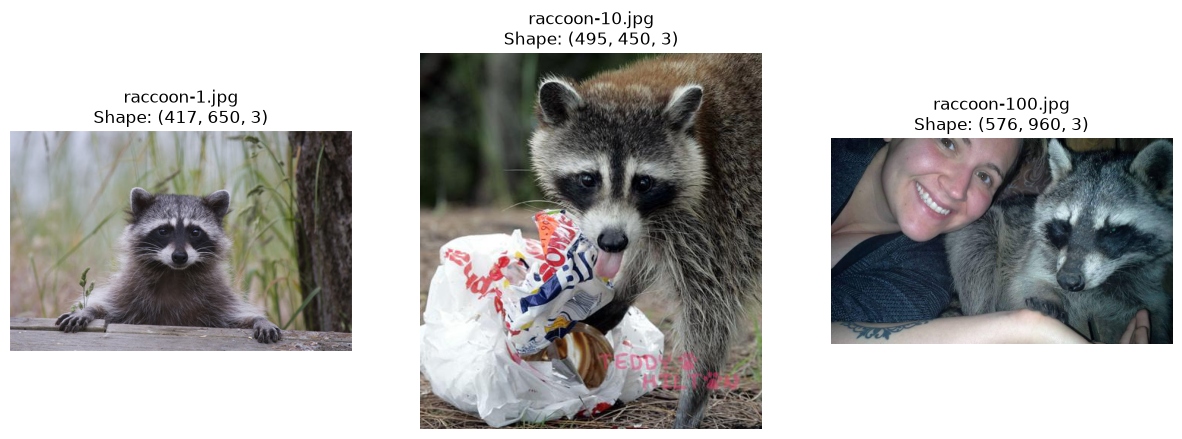

In [32]:
import matplotlib.image as mpimg

# Display Sample Images
image_dir = '/Users/vishwakarma/Downloads/raccoon_dataset/images'

img_files = sorted(f for f in os.listdir(image_dir) if os.path.isfile(os.path.join(image_dir, f)))[:3]
print(f"Image count: {img_files.__len__()}")

# Create a 1x3 grid to display the samples
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for index, img_name in enumerate(img_files):
    img_path = os.path.join(image_dir, img_name)
    img = mpimg.imread(img_path)

    axes[index].imshow(img)
    axes[index].set_title(f"{img_name}\nShape: {img.shape}")
    axes[index].axis('off')



In [35]:
import os
from xml.etree import ElementTree
import numpy as np
import tensorflow as tf


def extract_boxes(xml_path):
    tree = ElementTree.parse(xml_path)
    root = tree.getroot()
    boxes = []
    for box in root.findall('.//bndbox'):
        xmin = int(box.find('xmin').text)
        ymin = int(box.find('ymin').text)
        xmax = int(box.find('xmax').text)
        ymax = int(box.find('ymax').text)
        boxes.append([xmin, ymin, xmax, ymax])
    width = int(root.find('.//size/width').text)
    height = int(root.find('.//size/height').text)
    return boxes, width, height


def create_tf_example(image_id, img_path, ann_path):
    with tf.io.gfile.GFile(img_path, 'rb') as fid:
        encoded_jpg = fid.read()

    boxes, width, height = extract_boxes(ann_path)

    xmins, ymins, xmaxs, ymaxs = [], [], [], []
    classes_text, classes = [], []
    encoded_masks = []

    for box in boxes:
        xmin, ymin, xmax, ymax = box
        # Normalize coordinates as required by tf-models-official
        xmins.append(xmin / float(width))
        ymins.append(ymin / float(height))
        xmaxs.append(xmax / float(width))
        ymaxs.append(ymax / float(height))
        classes_text.append(b'raccoon')
        classes.append(1)

        # Create rectangular mask matching your original load_mask() logic
        mask = np.zeros((height, width, 1), dtype=np.uint8)
        mask[ymin:ymax, xmin:xmax, 0] = 1
        encoded_masks.append(tf.io.encode_png(mask).numpy())

    feature_dict = {
        'image/height': tf.train.Feature(
            int64_list=tf.train.Int64List(value=[height])
        ),
        'image/width': tf.train.Feature(
            int64_list=tf.train.Int64List(value=[width])
        ),
        'image/filename': tf.train.Feature(
            bytes_list=tf.train.BytesList(
                value=[os.path.basename(img_path).encode('utf8')]
            )
        ),
        'image/source_id': tf.train.Feature(
            bytes_list=tf.train.BytesList(value=[image_id.encode('utf8')])
        ),
        'image/encoded': tf.train.Feature(
            bytes_list=tf.train.BytesList(value=[encoded_jpg])
        ),
        'image/format': tf.train.Feature(
            bytes_list=tf.train.BytesList(value=[b'jpeg'])
        ),
        'image/object/bbox/xmin': tf.train.Feature(
            float_list=tf.train.FloatList(value=xmins)
        ),
        'image/object/bbox/xmax': tf.train.Feature(
            float_list=tf.train.FloatList(value=xmaxs)
        ),
        'image/object/bbox/ymin': tf.train.Feature(
            float_list=tf.train.FloatList(value=ymins)
        ),
        'image/object/bbox/ymax': tf.train.Feature(
            float_list=tf.train.FloatList(value=ymaxs)
        ),
        'image/object/class/text': tf.train.Feature(
            bytes_list=tf.train.BytesList(value=classes_text)
        ),
        'image/object/class/label': tf.train.Feature(
            int64_list=tf.train.Int64List(value=classes)
        ),
        'image/object/mask': tf.train.Feature(
            bytes_list=tf.train.BytesList(value=encoded_masks)
        ),
    }
    return tf.train.Example(features=tf.train.Features(feature=feature_dict))


def build_tfrecord(dataset_dir, output_path, is_train=True):
    images_dir = os.path.join(dataset_dir, 'images')
    annotations_prefix = os.path.join(dataset_dir, 'annotations', 'raccoon-')
    count = 0

    with tf.io.TFRecordWriter(output_path) as writer:
        for filename in sorted(os.listdir(images_dir)):
            if not filename.endswith(('.jpg', '.jpeg', '.png')):
                continue
            image_id = filename[8:-4]
            if image_id in ['00090']:
                continue
            if is_train and int(image_id) >= 150:
                continue
            if not is_train and int(image_id) < 150:
                continue

            img_path = os.path.join(images_dir, filename)
            ann_path = f'{annotations_prefix}{image_id}.xml'
            tf_example = create_tf_example(image_id, img_path, ann_path)
            writer.write(tf_example.SerializeToString())
            count += 1

    split_name = 'Train' if is_train else 'Test'
    print(f'{split_name}: {count} records written to {output_path}')


if __name__ == '__main__':
    build_tfrecord('/Users/vishwakarma/Downloads/raccoon_dataset/', 'train.tfrecord', is_train=True)
    build_tfrecord('/Users/vishwakarma/Downloads/raccoon_dataset/', 'val.tfrecord', is_train=False)


Train: 149 records written to train.tfrecord
Test: 51 records written to val.tfrecord


Image shape: (417, 650, 3)
Masks shape: (1, 417, 650)
Class IDs: [1]


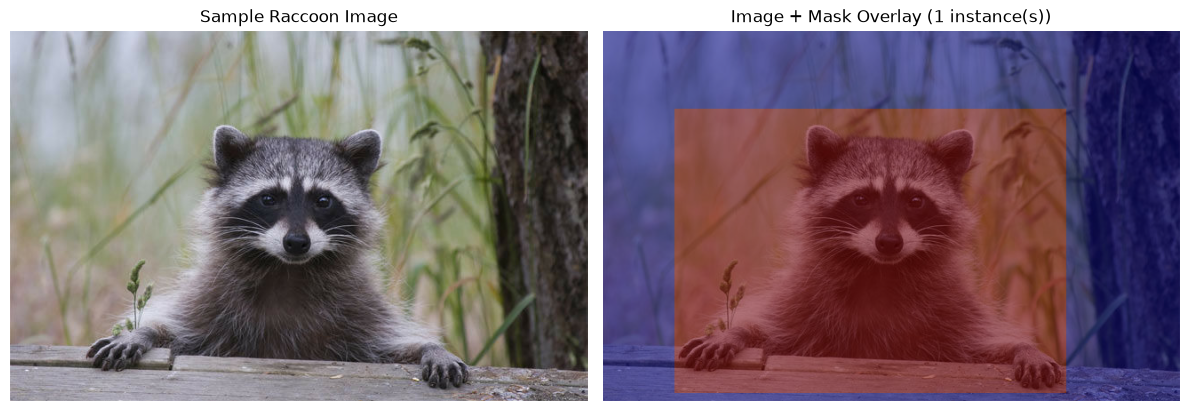

In [45]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from official.vision.dataloaders import tf_example_decoder

# 1. Initialize the official decoder with masks enabled
decoder = tf_example_decoder.TfExampleDecoder(include_mask=True)

# 2. Read one sample record from train.tfrecord
raw_dataset = tf.data.TFRecordDataset(['train.tfrecord'])
# print(raw_dataset)
for raw_record in raw_dataset.take(1):
    decoded = decoder.decode(raw_record)

# print(decoded)
# 3. Convert tensors to NumPy arrays for visualization
image = decoded['image'].numpy()
masks = decoded['groundtruth_instance_masks'].numpy()  # Shape: [N, H, W]
boxes = decoded['groundtruth_boxes'].numpy()
classes = decoded['groundtruth_classes'].numpy()

print('Image shape:', image.shape)
print('Masks shape:', masks.shape)
print('Class IDs:', classes)

# 4. Combine all instance masks into a single 2D mask for display
combined_mask = np.max(masks, axis=0) if masks.shape[0] > 0 else np.zeros(image.shape[:2])

# 5. Plot the original image and its mask side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(image)
axes[0].set_title('Sample Raccoon Image')
axes[0].axis('off')

axes[1].imshow(image)
axes[1].imshow(combined_mask, cmap='jet', alpha=0.5)
axes[1].set_title(f'Image + Mask Overlay ({masks.shape[0]} instance(s))')
axes[1].axis('off')

plt.tight_layout()
plt.show()


**Creating Annotations for a Custom Image**


The assignment provides annotation_tool.html for manually annotating an image. Open the HTML file in a browser, upload the raccoon image, draw a rectangle around the raccoon, and assign the class label raccoon.

The following is an example of the relevant VIA project-export structure with the class label populated. It illustrates the expected annotation data; it is not a screenshot or proof that the browser annotation tool was operated.

In [ ]:
# Raccoon image with YOLO annotation
{
    "_via_settings": {
        "ui": {
            "annotation_editor_height": 25,
            "annotation_editor_fontsize": 0.8,
            "leftsidebar_width": 18,
            "image_grid": {
                "img_height": 80,
                "rshape_fill": "none",
                "rshape_fill_opacity": 0.3,
                "rshape_stroke": "yellow",
                "rshape_stroke_width": 2,
                "show_region_shape": true,
                "show_image_policy": "all"
            },
            "image": {
                "region_label": "__via_region_id__",
                "region_color": "__via_default_region_color__",
                "region_label_font": "10px Sans",
                "on_image_annotation_editor_placement": "NEAR_REGION"
            }
        },
        "core": {
            "buffer_size": 18,
            "filepath": {},
            "default_filepath": ""
        },
        "project": {
            "name": "via_project_15Nov2026_8h47m"
        }
    },
    "_via_img_metadata": {
        "Raccoon_Cudjoe_Key_Florida.jpg30720": {
            "filename": "Raccoon_Cudjoe_Key_Florida.jpg",
            "size": 30720,
            "regions": [
                {
                    "shape_attributes": {
                        "name": "rect",
                        "x": 38,
                        "y": 29,
                        "width": 128,
                        "height": 80
                    },
                    "region_attributes": {}
                }
            ],
            "file_attributes": {}
        }
    },
    "_via_attributes": {
        "region": {},
        "file": {}
    }
}

In [52]:
import os

HOME = os.getcwd()
print("Working directory:", HOME)
print("**" * 10)

# Check system, Python, PyTorch, and GPU dependencies
import ultralytics

ultralytics.checks()


Ultralytics 8.4.212 🚀 Python-3.13.18 torch-2.15.0 CPU (Apple M5)
Setup complete ✅ (10 CPUs, 32.0 GB RAM, 117.7/460.4 GB disk)


In [48]:
from ultralytics import YOLO

# Load default pre-trained YOLOv10 nano weights (if specifically required by Part 3b)
model = YOLO("yolov10n.pt")

# Verify the model loaded properly by checking its class names (80 COCO classes)
print("Model loaded successfully. Number of classes:", len(model.names))


Model loaded successfully. Number of classes: 80


In [55]:
# Load default pre-trained YOLOv11 nano weights
model = YOLO("yolo11n.pt")

# Evaluate the model's performance on the validation set
metrics = model.val()

# Perform object detection on an image
results = model("/Users/vishwakarma/Downloads/bus.jpg")  # Predict on an image

# Display results in new window
results[0].show()

WARNING ⚠️ 'data' argument is missing. Using default 'data=coco8.yaml'.
Ultralytics 8.4.212 🚀 Python-3.13.18 torch-2.15.0 CPU (Apple M5)
YOLOv10n summary (fused): 99 layers, 2,299,264 parameters, 0 gradients, 6.8 GFLOPs

WARNING ⚠️ Dataset 'coco8.yaml' images not found, missing path '/Users/vishwakarma/Documents/Amit-MS-Stuff/datasets/coco8/images/val'
Unzipping /Users/vishwakarma/Documents/Amit-MS-Stuff/datasets/coco8.zip to /Users/vishwakarma/Documents/Amit-MS-Stuff/datasets/coco8...: 100% ━━━━━━━━━━━━ 25/25 5.5Kfiles/s 0.0s
Dataset download success ✅ (0.8s), saved to /Users/vishwakarma/Documents/Amit-MS-Stuff/datasets

val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1192.2±260.6 MB/s, size: 54.0 KB)
val: Scanning /Users/vishwakarma/Documents/Amit-MS-Stuff/datasets/coco8/labels/val... 4 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4/4 1.8Kit/s 0.0s
val: New cache created: /Users/vishwakarma/Documents/Amit-MS-Stuff/datasets/coco8/labels/val.cache
                 Class     Im

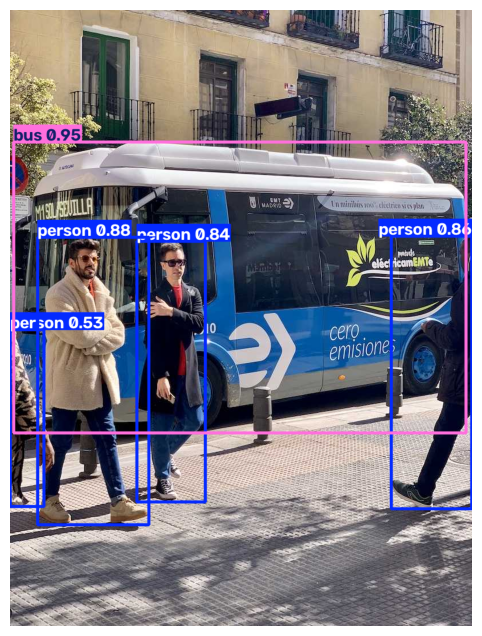

In [57]:
# Display results in notebook
import cv2

# Generate the annotated image array (returns BGR format)
annotated_img = results[0].plot()

# Convert BGR (OpenCV default) to RGB (Matplotlib default)
annotated_img_rgb = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)

# Display directly inside the Jupyter Notebook
plt.figure(figsize=(10, 8))
plt.imshow(annotated_img_rgb)
plt.axis('off')
plt.show()

WARNING ⚠️ Checkpoint dataset '/usr/src/ultralytics/ultralytics/cfg/datasets/coco.yaml' was not found. Using default 'data=coco8.yaml'. Pass data=... to validate on the original dataset.
Ultralytics 8.4.212 🚀 Python-3.13.18 torch-2.15.0 CPU (Apple M5)
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 363.9±165.4 MB/s, size: 54.0 KB)
val: Scanning /Users/vishwakarma/Documents/Amit-MS-Stuff/datasets/coco8/labels/val.cache... 4 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4/4 986.9Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 6.7it/s 0.1s
                   all          4         17       0.57       0.85      0.854      0.631
                person          3         10      0.557        0.6       0.63      0.273
                   dog          1          1      0.548          1      0.995      0.697
                 horse  

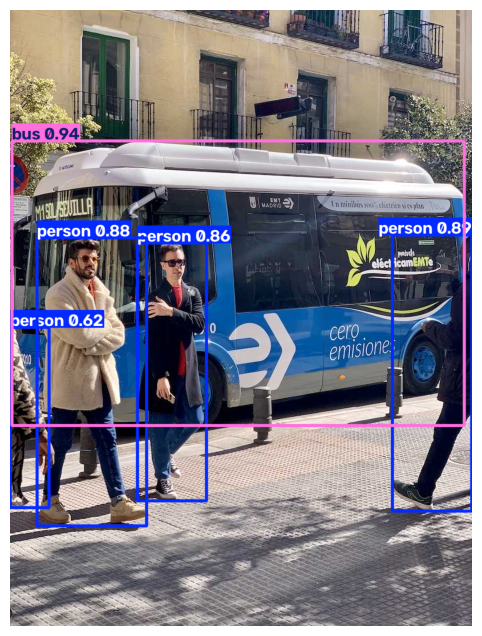

In [58]:
# Load default pre-trained YOLOv11 nano weights
model_11 = YOLO("yolo11n.pt")

# Evaluate the model's performance on the validation set
metrics = model_11.val()

# Perform object detection on an image
results_model_11 = model_11("/Users/vishwakarma/Downloads/bus.jpg")  # Predict on an image

# Display results in notebook
# Generate the annotated image array (returns BGR format)
annotated_img_model_11 = results_model_11[0].plot()

# Convert BGR (OpenCV default) to RGB (Matplotlib default)
annotated_img_rgb_model_11 = cv2.cvtColor(annotated_img_model_11, cv2.COLOR_BGR2RGB)

# Display directly inside the Jupyter Notebook
plt.figure(figsize=(10, 8))
plt.imshow(annotated_img_rgb_model_11)
plt.axis('off')
plt.show()

In [59]:
# Load default pre-trained YOLOv11 nano weights
model_11_wildlife = YOLO("yolo11n.pt")

# Evaluate the model's performance on the validation set
metrics = model_11_wildlife.val()

# Fine-tune on african-wildlife.yaml for 10 epochs with batch size 32
train_results = model_11_wildlife.train(
    data="african-wildlife.yaml",
    epochs=10,
    batch=32,
    imgsz=640
)


WARNING ⚠️ Checkpoint dataset '/usr/src/ultralytics/ultralytics/cfg/datasets/coco.yaml' was not found. Using default 'data=coco8.yaml'. Pass data=... to validate on the original dataset.
Ultralytics 8.4.212 🚀 Python-3.13.18 torch-2.15.0 CPU (Apple M5)
YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 398.9±133.8 MB/s, size: 54.0 KB)
val: Scanning /Users/vishwakarma/Documents/Amit-MS-Stuff/datasets/coco8/labels/val.cache... 4 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4/4 1.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 8.0it/s 0.1s
                   all          4         17       0.57       0.85      0.854      0.631
                person          3         10      0.557        0.6       0.63      0.273
                   dog          1          1      0.548          1      0.995      0.697
                 horse    

Results saved in: /Users/vishwakarma/Documents/Amit-MS-Stuff/applied_computer_vision_for_AI_course/runs/detect/train


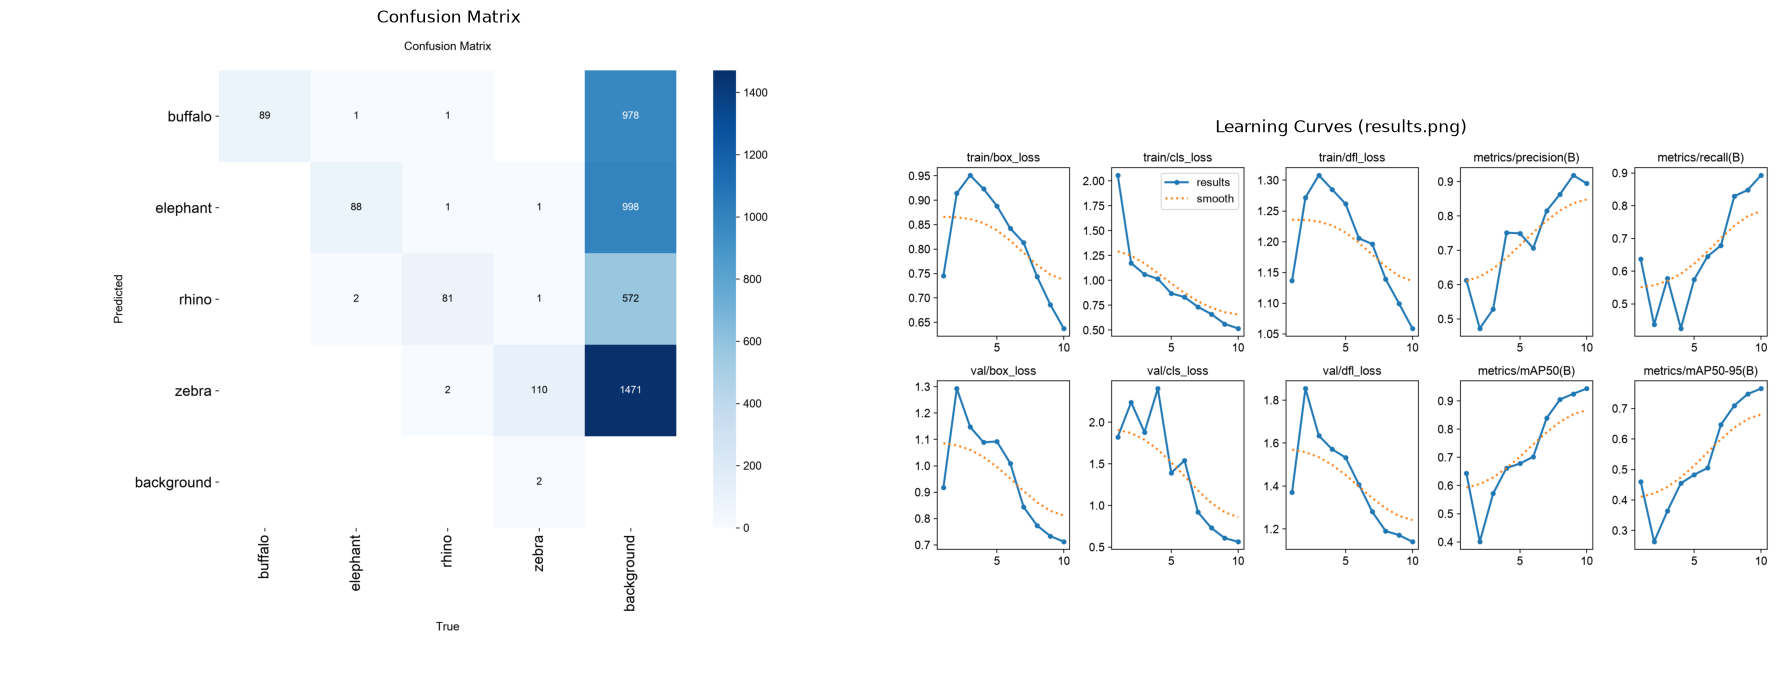

In [60]:
import matplotlib.image as mpimg

# Automatically get the exact save directory (e.g., runs/detect/train)
save_dir = str(train_results.save_dir)
print("Results saved in:", save_dir)

# Paths to the confusion matrix and learning curve PNGs
conf_matrix_path = os.path.join(save_dir, "confusion_matrix.png")
results_curve_path = os.path.join(save_dir, "results.png")

# Display both plots side by side in the notebook
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Plot 1: Confusion Matrix
axes[0].imshow(mpimg.imread(conf_matrix_path))
axes[0].set_title("Confusion Matrix")
axes[0].axis("off")

# Plot 2: Learning Curves (Loss & mAP)
axes[1].imshow(mpimg.imread(results_curve_path))
axes[1].set_title("Learning Curves (results.png)")
axes[1].axis("off")

plt.tight_layout()
plt.show()


## Analysis of Learning Curves and Confusion Matrix

### 1. Learning Curves

The `results.png` figure tracks the training losses, validation losses, precision, recall, and mean Average Precision (mAP) over the 10 training epochs.

**Training and validation losses**

- The training box loss decreases from approximately **0.75 to 0.64**.
- The training classification loss decreases from approximately **2.05 to 0.52**.
- The training DFL loss decreases from approximately **1.14 to 1.06**.
- The validation box, classification, and DFL losses fluctuate during the early epochs but show an overall downward trend by the final epoch.

The decreasing training losses indicate that the model is learning to localize objects and classify the wildlife categories. The validation-loss fluctuations are normal during training, especially with a relatively small number of epochs.

**Detection metrics**

The final validation metrics reported by Ultralytics for the best checkpoint are:

| Metric | Result |
|---|---:|
| Precision | 0.894 |
| Recall | 0.893 |
| mAP@50 | 0.944 |
| mAP@50–95 | 0.765 |

Precision of 0.894 indicates that most predicted detections are correct, while recall of 0.893 indicates that the model detects most of the annotated objects. The mAP@50 score of 0.944 indicates strong detection performance at an IoU threshold of 0.50. The lower mAP@50–95 score of 0.765 reflects the stricter evaluation across multiple IoU thresholds.

The metric curves improve overall, although precision and recall fluctuate between epochs. This suggests that the model is learning effectively, but additional training and evaluation would be needed to determine whether performance can improve further.

### 2. Confusion Matrix

The confusion matrix compares the predicted classes (vertical axis) with the true classes (horizontal axis). Its main diagonal represents correctly classified detections.

The displayed matrix shows the following diagonal counts:

- **Buffalo:** 89 correct detections
- **Elephant:** 88 correct detections
- **Rhino:** 81 correct detections
- **Zebra:** 110 correct detections

There are only a few visible off-diagonal animal-to-animal errors. For example, a small number of elephant and rhino instances are confused with other animal categories.

The background column contains large counts for predictions assigned to animal classes when the true class is background. These are false-positive detections and indicate that the model sometimes identifies background regions as animals. The background row shows two missed zebra instances in the displayed matrix, which are false negatives.

Therefore, although the model classifies the four animal categories well in many cases, reducing background-related false positives is an area for further improvement.

### 3. Overall Conclusion

The experiment demonstrates how transfer learning can adapt a pretrained YOLO11 model to a custom wildlife detection dataset. After 10 epochs with a batch size of 32, the model achieved **89.4% precision, 89.3% recall, 94.4% mAP@50, and 76.5% mAP@50–95** on the validation set.

The learning curves show an overall reduction in losses and improvement in detection metrics. The confusion matrix indicates strong diagonal counts for the four animal categories, while also highlighting background-related false positives as an area that could be improved.

Further training, data augmentation, and threshold tuning could be explored to improve the model's generalization and reduce false-positive detections.